# The supervisory stress-test models, vine copulas, growth-at-risk and Bayesian VARs

**Question:** Next to the published practice for aggregating risks and measuring model risk, how much does one capital figure of
Banco Andino hide, and how far could the reference model be wrong before its capital changes?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 01 to 03 of this topic (the aggregation, the band and its bounds)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- simulate the Gaussian aggregate of Banco Andino's four risks and read its capital, the one figure that the published
  measures of model risk will question;
- read the published practice around supervisory stress-test models, scenario generators, risk aggregation and model risk, and
  say what the case implements and what it leaves out;
- run the Barrieu and Scandolo add-on multiplier and relative measure over the eight models of the band, and read what they say
  about the spread among the models;
- run the Glasserman and Xu worst case within an entropy budget on the simulated aggregate, and say how fast it grows;
- compare the case with the published practice on the numbers that can be measured on the committed documents.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 statsmodels==0.15.0
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the aggregation block of **C18** (Banco Andino), as notebooks 01 to 03 do.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.1.0 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginals, band, correlation matrix, and the committed `model_risk` block with the Barrieu-Scandolo and Glasserman-Xu results; and `outputs.backcast` for the satellites' out-of-time fit), `data/derived/C18/t-copula-baseline.json` (the Rosenberg and Schuermann reference) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`).
- **The marginals are rebuilt from the committed quantile grids, for one step.** The Glasserman-Xu measure needs the simulated losses of the aggregate, which the document does not hold, so step 2 rebuilds the marginals of notebook 02 from the grids and simulates the Gaussian aggregate with the case's seed; the committed numbers are printed beside it.

In [2]:
# The aggregation block of the baseline, the correlation matrix, the band and the committed quantile grids
baseline_doc = read_json("C18/baseline.json")
agg = baseline_doc["outputs"]["aggregation"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
R = np.array(agg["correlation"]["matrix"])
band = agg["band"]
marginals = agg["marginals"]
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum",
         "variance-covariance": "variance-covariance", "gaussian-copula": "Gaussian copula (reference)",
         "t-copula": "t copula", "worst-case": "worst case"}

## Method

### Step 1: the capital that is questioned

The case's own method is the aggregation of notebooks 01 to 03: four marginals, a correlation matrix, a copula, and one
capital figure with a band around it. This step runs it once more, as notebook 02 did: the four quantile functions are
rebuilt from the committed grids and `simulate_component_losses` draws one million joint losses under the Gaussian copula with
the case's seed. The next two cells simulate, and then read the VaR, the expected shortfall and the economic capital of the
total with the engine's estimators.

In [3]:
# Rebuild the marginals from the committed grids and simulate the Gaussian aggregate of the four risks
LEVEL = 0.999
probs = np.array(grid["probabilities"])
ppfs = [partial(np.interp, xp=probs, fp=np.array(q["quantiles"])) for q in grid["marginals"]]
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, 1_000_000, 42, 100_000)
total = joint.sum(axis=1)
print("simulated scenarios and risks", joint.shape)

simulated scenarios and risks (1000000, 4)


The next cell reads the VaR and the expected shortfall of the total with the engine's estimators and draws the histogram of
the total on a log scale with both marked.

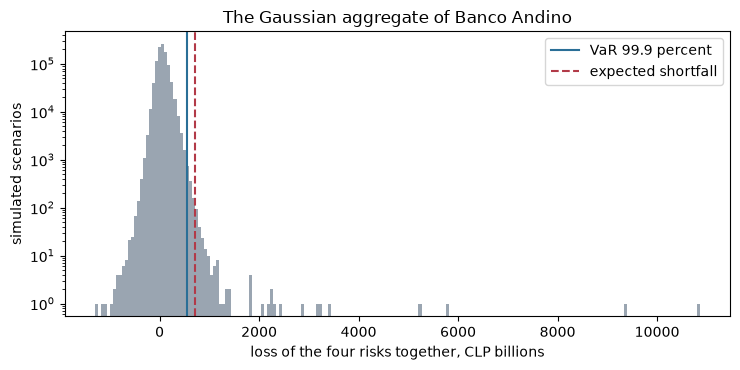

mean, VaR and ES of the total, CLP millions
66898.7 558727.5 709402.5
economic capital, VaR less expected loss 491998.8


In [4]:
# The VaR and expected shortfall of the total with the engine's estimators, and the histogram of the total
var_total = rv_port.var_from_sample(total, LEVEL)
es_total = rv_port.es_from_sample(total, LEVEL)
el_total = sum(m["el_clp_m"] for m in marginals)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(total / 1e3, bins=200, color="#9aa5b1", log=True)
ax.axvline(var_total / 1e3, color="#2a6f97", label="VaR 99.9 percent")
ax.axvline(es_total / 1e3, color="#b23a48", linestyle="--", label="expected shortfall")
ax.set_xlabel("loss of the four risks together, CLP billions")
ax.set_ylabel("simulated scenarios")
ax.set_title("The Gaussian aggregate of Banco Andino")
ax.legend()
fig.tight_layout()
plt.show()
print("mean, VaR and ES of the total, CLP millions")
print(round(total.mean(), 1), round(var_total, 1), round(es_total, 1))
print("economic capital, VaR less expected loss", round(var_total - el_total, 1))

The mean of the total is CLP 66,899 million, which is its expected loss, and the 99.9 percent VaR is far to the right, at
CLP 558,727 million, with the expected shortfall further still: the tail is heavy, because operational risk and credit risk
carry long right tails. Subtracting the expected loss gives the economic capital of the Gaussian copula, the reference model
of this notebook. Everything below asks the same question of this one number, how much of it is the model.

## Comparison

The persisted research (dossiers 05 and 06) states the practice around each part of the case. The table puts it beside what the case does, with the source and the status of each statement.

| Part | The published practice | In the case and in the engine |
|---|---|---|
| **Supervisory stress-test models** | The Federal Reserve now publishes full model documentation (Fall 2026, credit risk models). Corporate expected loss is $PD \times LGD \times EAD$ per facility; the PD model is a set of 16 OLS regressions of vendor PD on the BBB spread and its four-quarter lag, estimated 2006 to 2023; LGD is stressed through the BBB spread, EAD through a loan-equivalent factor on Shared National Credit data; PPNR has its own 2026 model suite. | Five OLS satellites of charge-off rates by loan type on GDP growth and unemployment, fitted 1985 to 2019 (notebook 04): a simpler, different family. The Federal Reserve models **cannot be replicated to a published loss rate** from the public record, which is why case C19 stays planned (notebook 09). |
| **Bottom-up under constraints** | The EBA 2025 exercise is a constrained bottom-up stress test: banks use their own models under prescribed parameters, with a static balance sheet and benchmark parameters where no adequate satellite exists (Methodological Note, paragraphs 33 to 38 and 122 to 124). | The static rules by paragraph are applied and tested (notebook 05); the case has one bank and no challenger, so bottom-up against top-down is a rule shown, not a comparison made (notebook 07). |
| **Scenario generators** | Bayesian VARs with Minnesota priors (Litterman 1986; Banbura, Giannone and Reichlin 2010), global VARs, growth-at-risk with a skewed-t density (Adrian, Boyarchenko and Giannone 2019) and a panel quantile satellite (Covas, Rump and Zakrajsek 2014). | The engine has the VAR conditional forecast and the skewed-t step of growth-at-risk (notebook 04); the quantile-regression step needs `statsmodels`, absent from this environment; the Minnesota BVAR and the panel quantile satellite are deferred (backlog item BL-078). |
| **Risk aggregation** | Rosenberg and Schuermann (2006): total risk is more sensitive to the business mix than to the inter-risk correlations, the copula choice has a modest effect, and the additive approximation overestimates risk by about 30 to 40 percent. The Joint Forum found aggregation models "a work in progress" on which supervisors generally do not rely (the press release of 21 October 2010, https://www.bis.org/press/p101021.htm, gives both phrases). Vine copulas are available offline in `pyvinecopulib`. | The ladder from the simple sum to the worst case (notebooks 01 to 03), and the reference of Rosenberg and Schuermann read beside the result. The engine has Gaussian and t copulas and the closed forms of Clayton; **vine copulas are not in the engine** (BL-078) and `pyvinecopulib` is not in this environment. |
| **Model-risk quantification** | Barrieu and Scandolo (2015) and Glasserman and Xu (2014), as above; quantitative model-risk measures are sensitivity information, never a regulatory capital figure. | Both are in the engine and run in steps 1 and 2; the case labels them `information-not-capital`. |

The first two rows of the table concern models the case cannot run, the Federal Reserve's and the EBA's, and the third and the
fourth concern tools the engine lacks in part; the last row, model risk, is run in the two steps below, and the next cell then
measures what the committed documents let it measure.

### Measure 1: model risk over the set of aggregation models

The band of notebook 03 is a **set of models** for one quantity (the capital): the square-root rule, the Gaussian copula, three t copulas, and the two bounds. A single figure hides the spread among them, and the literature has measures of that spread (Barrieu and Scandolo, 2015). Let $\rho(X_0)$ be the measure under the **reference model**, and $\overline\rho$ and $\underline\rho$ its largest and smallest value over the set $\mathcal L$. Then

$$\mathrm{AM} = \frac{\overline\rho}{\rho(X_0)} - 1, \qquad \mathrm{RM} = \frac{\overline\rho - \rho(X_0)}{\overline\rho - \underline\rho} \in [0, 1].$$

The **add-on multiplier** AM generalises the Basel multiplier: multiplying the reference capital by $1 + \mathrm{AM}$ reaches the worst case in the set. The **relative measure** RM says where the reference sits between the best and worst case: 0 at the worst, 1 at the best. In the case the reference is the Gaussian copula and the set is the eight rows of the band, as sensitivity **information, not capital**.

The next cell calls `barrieu_scandolo` over the eight capitals of the band with the Gaussian copula as the reference and
offers it a reference index outside the set.

In [5]:
# Barrieu-Scandolo add-on multiplier and relative measure over the eight band rows
capitals = [row["capital_clp_m"] for row in band]
labels = [(row["method"], row["nu"]) for row in band]
reference = labels.index(("gaussian-copula", None))
measures = model_risk.barrieu_scandolo(capitals, reference)
committed_bs = agg["model_risk"]["barrieu_scandolo"]
print("reference capital, worst and best in the set")
print(round(measures.rho_x0, 1), round(measures.rho_max, 1), round(measures.rho_min, 1))
print("AM", round(measures.am, 6), "RM", round(measures.rm, 6))
print("committed AM and RM", round(committed_bs["am"], 6), round(committed_bs["rm"], 6))
print("reference times 1 + AM", round(measures.rho_x0 * (1 + measures.am), 1))
print("1 + AM and RM, percent", round(1 + measures.am, 2), round(measures.rm * 100))
try:
    model_risk.barrieu_scandolo(capitals, len(capitals))
except ValueError:
    print("a reference index outside the set is refused")

reference capital, worst and best in the set
491973.5 823331.5 118517.5
AM 0.673528 RM 0.470135
committed AM and RM 0.673528 0.470135
reference times 1 + AM 823331.5
1 + AM and RM, percent 1.67 47
a reference index outside the set is refused


The next cell draws the eight capitals as multiples of the Gaussian reference, with the range that the published additive
overestimate would give shaded.

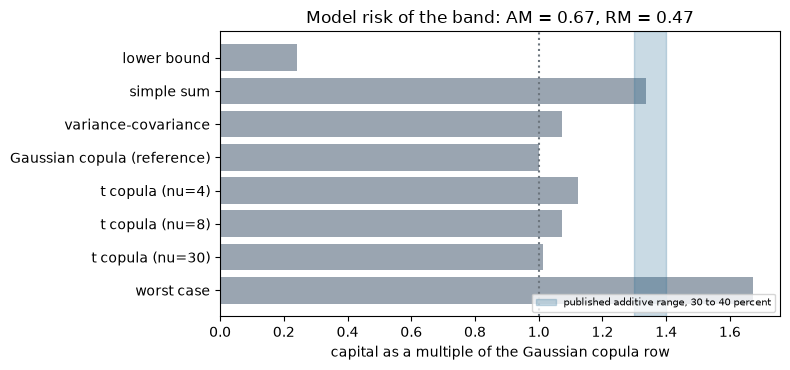

In [6]:
# The band as a multiple of the Gaussian reference, with the published additive range shaded
multiple = [c / measures.rho_x0 for c in capitals]
names = [NAMES[m] + (f" (nu={nu:g})" if nu else "") for m, nu in labels]
published = "published additive range, 30 to 40 percent"
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], multiple[::-1], color="#9aa5b1")
ax.axvspan(1.30, 1.40, color="#2a6f97", alpha=0.25, label=published)
ax.axvline(1.0, color="#6c757d", linestyle=":")
ax.set_xlabel("capital as a multiple of the Gaussian copula row")
ax.set_title(f"Model risk of the band: AM = {measures.am:.2f}, RM = {measures.rm:.2f}")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

The set of models is wide. The Gaussian reference is CLP 491,974 million and the eight rows run from 118,518 million, the
lower bound, to 823,332 million, the worst case, a ratio of 6.95. The add-on multiplier is 0.6735, so multiplying the reference
by 1.67 reaches the worst case, and the relative measure is 0.4701: the reference sits 47 percent of the way down from the worst
case to the best. The shaded band is what Rosenberg and Schuermann would expect for the simple sum over a diversified figure,
and the simple sum bar falls in it, but the spread of the set is far wider than the paper's range.

### Measure 2: the worst case within an entropy budget

Barrieu and Scandolo's set is the set of models the analyst wrote down. Glasserman and Xu (2014) ask a different question: **how wrong can the reference model be, in a measurable way, before a quantity changes by how much?** Take the baseline law of a loss $V$ (here the aggregate of the Gaussian copula) and consider every alternative law with likelihood ratio $m \ge 0$, $E[m] = 1$, whose **relative entropy** from the baseline is at most a budget $\eta$. The worst expected loss is

$$\sup_{m \ge 0,\ E[m\log m] \le \eta} E[m\,V], \qquad m_\theta = \frac{e^{\theta V}}{E[e^{\theta V}]},$$

with $\theta > 0$ chosen so that the entropy constraint binds: the worst case **tilts** the baseline sample towards its large losses, exponentially. It costs only a reweighting of the baseline simulation. `glasserman_xu_worst_case(v, budget)` returns the tilt $\theta$, the entropy reached, the baseline mean and the worst-case mean, and refuses a budget the sample cannot reach (the entropy of a tilt is at most $\log S$).

The case uses the budget $\eta = 0.05$ on the Gaussian aggregate.

The next cell runs `glasserman_xu_worst_case` on the simulated aggregate of step 1 for budgets from 0.005 to 0.25, prints four
of them and the refusal of an unreachable one.

In [7]:
# The Glasserman-Xu worst case within an entropy budget: a sweep of budgets, four of them printed, one refusal
budgets = np.linspace(0.005, 0.25, 25)
runs = [model_risk.glasserman_xu_worst_case(total, b) for b in budgets]
print("budget, tilt, entropy, baseline, worst case, ratio")
for budget in (0.01, 0.05, 0.1, 0.2):
    gx = model_risk.glasserman_xu_worst_case(total, budget)
    row = (budget, gx.theta, gx.relative_entropy, gx.baseline, gx.worst_case, gx.worst_case / gx.baseline)
    print("%5.2f %10.3e %7.4f %11.1f %11.1f %5.2f" % row)
committed_gx = agg["model_risk"]["glasserman_xu"]
print("committed, budget 0.05")
print(round(committed_gx["baseline_clp_m"], 1), round(committed_gx["worst_case_clp_m"], 1))
try:
    model_risk.glasserman_xu_worst_case(total[:50], 10.0)
except ValueError:
    print("a budget the sample cannot reach is refused")

budget, tilt, entropy, baseline, worst case, ratio
 0.01  6.367e-07  0.0100     66898.7     88454.2  1.32
 0.05  7.878e-07  0.0500     66898.7    143206.7  2.14
 0.10  8.497e-07  0.1000     66898.7    204035.3  3.05
 0.20  9.114e-07  0.2000     66898.7    317194.7  4.74
committed, budget 0.05
66898.5 143201.8
a budget the sample cannot reach is refused


The next cell draws the worst expected loss of the sweep as a multiple of the baseline, with the case's budget marked.

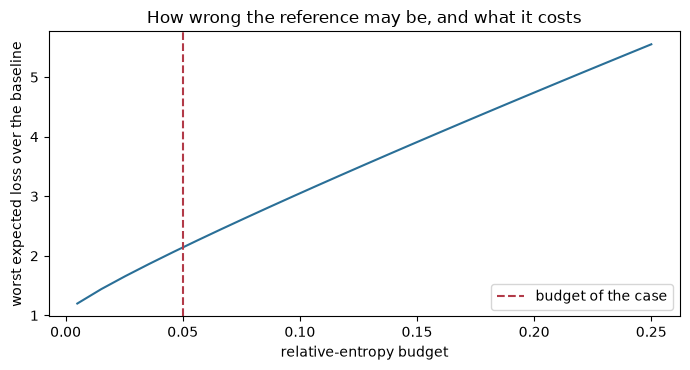

In [8]:
# The worst expected loss over the baseline as the entropy budget grows
ratio = [r.worst_case / r.baseline for r in runs]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(budgets, ratio, color="#2a6f97")
ax.axvline(0.05, color="#b23a48", linestyle="--", label="budget of the case")
ax.set_xlabel("relative-entropy budget")
ax.set_ylabel("worst expected loss over the baseline")
ax.set_title("How wrong the reference may be, and what it costs")
ax.legend()
fig.tight_layout()
plt.show()

The entropy budget turns a modelling doubt into a number. On the simulated aggregate, whose baseline mean is CLP 66,899
million, the worst expected loss within a budget of 0.01, 0.05, 0.10 and 0.20 is 88,454, 143,207, 204,035 and 317,195, which is
1.32, 2.14, 3.05 and 4.74 times the baseline. At the case's budget of 0.05 it matches the committed block, 143,202. The curve
is convex: the worst case grows faster than the budget because the aggregate is heavy-tailed, and the more tail the baseline
has, the more a given budget can move its mean. A budget the sample cannot reach, above log S of 3.91, is refused.

### Measuring the rest of the table

The next cell reads from the committed documents what each remaining row of the table can be measured on: the additive
overestimate against the published range of Rosenberg and Schuermann, the spread of the copula rows over the Gaussian one, the
business mix of the capital, and the back-cast peak ratios of the satellites that stand for the supervisory-model row.

In [9]:
# Measure on the committed documents what each remaining row of the table can be measured on
gaussian = next(r["capital_clp_m"] for r in band if r["method"] == "gaussian-copula")
simple_sum = agg["headline"]["capital_clp_m"]
reference_doc = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
overestimate = agg_tests.rosenberg_schuermann_reference(simple_sum, gaussian)
print("additive overestimate (engine)", round(overestimate.statistic, 4))
print("published range", reference_doc["published_additive_overestimate"])
copula_rows = [r["capital_clp_m"] for r in band if r["method"] in ("gaussian-copula", "t-copula")]
print("spread of the copula rows over the Gaussian row", round(max(copula_rows) / gaussian - 1, 4))
mix = {m["risk"]: round(m["ec_clp_m"] / simple_sum, 3) for m in marginals}
print("business mix, share of the simple sum", mix)
capitals_all = [r["capital_clp_m"] for r in band]
print("worst case over lower bound", round(max(capitals_all) / min(capitals_all), 2))
backcast = baseline_doc["outputs"]["backcast"]["per_loan_type"]
peaks = [round(b["metrics"]["peak_predicted"] / b["metrics"]["peak_realised"], 2) for b in backcast]
print("back-cast peak ratios", peaks)

additive overestimate (engine) 0.3376
published range {'low': 0.3, 'high': 0.4}
spread of the copula rows over the Gaussian row 0.1228
business mix, share of the simple sum {'credit': 0.396, 'market': 0.431, 'irrbb': 0.111, 'operational': 0.063}
worst case over lower bound 6.95
back-cast peak ratios [4.55, 13.14, 252.13, 4.3, 2.09]


### A VAR conditional forecast and growth-at-risk beside the satellites

The stress satellites of this case are OLS regressions of each loan type's charge-off rate, through its link, on the
macroeconomic path of the scenario. The research (dossier 05) names two current methods the Board's own practice and the
literature use beside them. A vector autoregression treats the rate, unemployment and GDP growth as one system, so a scenario given
for GDP alone moves unemployment and the rate through the estimated dynamics: the conditional forecast of Waggoner and Zha (1999),
which the engine's `stress.scenario_models` implements period by period. Growth-at-risk (Adrian, Boyarchenko and Giannone 2019)
regresses the growth of the next year on current conditions at several quantiles, so the left tail can respond to financial
conditions more than the median does. The product runs both on the Board's history (`pipeline.cases.c18.stress_rungs`); that
history is read from the data root, so this notebook first runs the two methods on a system whose answer is known.

In [10]:
# A known VAR(1) of quarterly GDP growth (%), the unemployment rate (%) and the probit of a charge-off rate, fitted
from riskvalidation.stress import scenario_models as sm
from scipy.stats import norm

A = np.array([[0.45, -0.10, 0.00], [-0.12, 0.92, 0.00], [-0.035, 0.030, 0.88]])
c = np.array([1.6, 0.55, -0.38])
cov = np.array([[2.2, -0.25, -0.02], [-0.25, 0.09, 0.004], [-0.02, 0.004, 0.0025]])
mean = np.linalg.solve(np.eye(3) - A, c)
rng = np.random.default_rng(20261030)
y = np.empty((140, 3))
y[0] = mean
shocks = rng.multivariate_normal(np.zeros(3), cov, size=140)
for t in range(1, 140):
    y[t] = c + A @ y[t - 1] + shocks[t]
train = y[:132]
fit = sm.fit_var(train, 1)
error = np.array(fit.coefficients[0]) - A
rate_label = "charge-off rate at the mean of the system"
print(f"{rate_label}: {100 * norm.cdf(mean[2]):.3f} %")
for name, row in zip(("GDP growth equation", "unemployment equation", "rate equation"), error):
    print(f"{name:22s}", " ".join(f"{v:+.3f}" for v in row))


charge-off rate at the mean of the system: 0.150 %
GDP growth equation    +0.018 +0.392 +0.801
unemployment equation  -0.015 -0.127 -0.051
rate equation          -0.002 +0.001 -0.004


The system's mean puts the charge-off rate at 0.149 %, a quiet book. The fitted rate equation is within a few thousandths
of its true coefficients, while the GDP equation's coefficients on unemployment and on the rate are off by 0.392 and 0.801: those two
series barely move from quarter to quarter, so 132 quarters say little about their effect on growth. A conditional forecast reads
the rate equation, which is the one the fit gets right. The next cell imposes a recession on GDP alone and lets the system carry it
to the rate.

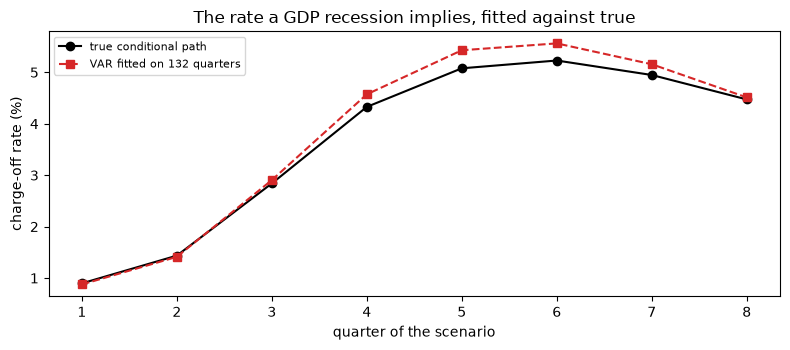

fitted 0.88 1.41 2.90 4.57 5.43 5.56 5.16 4.51
true   0.90 1.44 2.84 4.33 5.08 5.23 4.95 4.47


In [11]:
# A recession given for GDP alone over eight quarters: the fitted and the true conditional paths of the rate
path = np.array([[-2.5], [-6.0], [-4.0], [-1.0], [0.5], [1.5], [2.0], [2.2]])
fitted = sm.var_conditional_forecast(fit, train[-1:], path, [0])
true = np.empty((8, 3))
prev = train[-1]
for h in range(8):
    free = c + A @ prev
    shock_gdp = path[h, 0] - free[0]
    true[h] = np.r_[path[h, 0], free[1:] + cov[1:, 0] / cov[0, 0] * shock_gdp]
    prev = true[h]
quarters = np.arange(1, 9)
fig, ax = plt.subplots(figsize=(8, 3.6))
true_label = "true conditional path"
fitted_label = "VAR fitted on 132 quarters"
ax.plot(quarters, 100 * norm.cdf(true[:, 2]), color="black", marker="o", label=true_label)
ax.plot(quarters, 100 * norm.cdf(fitted[:, 2]), "--", color="tab:red", marker="s", label=fitted_label)
ax.set_xlabel("quarter of the scenario")
ax.set_ylabel("charge-off rate (%)")
ax.set_title("The rate a GDP recession implies, fitted against true")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("fitted", " ".join(f"{v:.2f}" for v in 100 * norm.cdf(fitted[:, 2])))
print("true  ", " ".join(f"{v:.2f}" for v in 100 * norm.cdf(true[:, 2])))


The fitted conditional path follows the true one: both rise from about 0.9 % to a peak in the sixth quarter, 5.56 % fitted
against 5.23 % true, and fall back as GDP recovers. The gap, a third of a point at the peak, comes from the estimated persistence of
the rate (its own lag coefficient), which a VAR needs to carry a shock forward. The OLS satellite would need the
unemployment path as an input; here the system supplies it, which is the reason to use a VAR, and also its risk: an error in the
dynamics enters every quarter of the scenario.

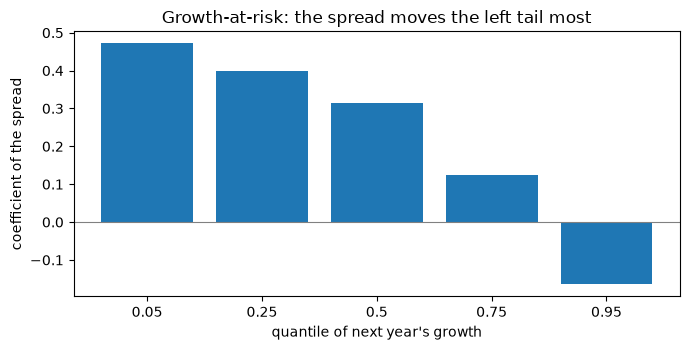

slope on the spread +0.472 +0.398 +0.314 +0.124 -0.165
held-out coverage   0.080 0.267 0.533 0.753 0.953
skewed t of the first origin: mu 2.159, sigma 0.996, alpha 0.864, nu 4.55


In [12]:
# Growth-at-risk: quantile regressions of next year's growth on current growth and a spread that widens the left tail
n = 600
g_now = rng.normal(2.0, 1.5, n)
spread = rng.normal(1.0, 1.0, n)
width = 0.8 + 0.6 * np.exp(-spread)
g_next = 0.6 + 0.6 * g_now + 0.3 * spread + width * rng.standard_t(6, n) * 0.8
X = np.column_stack([np.ones(n), g_now, spread])
taus = (0.05, 0.25, 0.5, 0.75, 0.95)
coef = sm.gar_quantile_regressions(g_next[:450], X[:450], taus)
q = X[450:] @ coef.T
cover = [(g_next[450:] < q[:, k]).mean() for k in range(len(taus))]
first = sm.fit_skewed_t_to_quantiles(q[0], taus)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([str(t) for t in taus], coef[:, 2], color="tab:blue")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("quantile of next year's growth")
ax.set_ylabel("coefficient of the spread")
ax.set_title("Growth-at-risk: the spread moves the left tail most")
fig.tight_layout()
plt.show()
print("slope on the spread", " ".join(f"{v:+.3f}" for v in coef[:, 2]))
print("held-out coverage  ", " ".join(f"{v:.3f}" for v in cover))
shape = f"mu {first.mu:.3f}, sigma {first.sigma:.3f}, alpha {first.alpha:.3f}, nu {first.nu:.2f}"
print("skewed t of the first origin:", shape)


The spread's coefficient falls from +0.472 at the 5 % quantile to -0.165 at the 95 % one: a narrow spread (low values) pulls
the left tail of next year's growth down much more than the median, which is the vulnerability growth-at-risk is built to find.
The quantiles fitted on 450 origins cover 0.080, 0.267, 0.533, 0.753 and 0.953 of the 150 held-out ones, near their nominal levels,
and the skewed Student-t fitted to the first origin's quantiles has a negative skew (alpha 0.864) and 4.55 degrees of freedom. The
product's back-cast on the Board's history is the test that counts.

In [13]:
# The product's back-cast of both rungs on the Board's history (C18): the windows, the sign checks, the verdicts
stress = next(m for m in read_json("C18/models-banco-andino.json")["model"] if "var" in m.get("details", {}))
details = stress["details"]
closer_label = "closer than OLS"
red_label = "sign checks red"
wrong_label = "coefficients of the wrong sign"
for w in details["var"]["summary"]:
    closer = f"{w['var_closer']} / {w['loan_types']}"
    print(f"{w['window_id']:14s} VAR {closer_label} {closer} | {red_label} {w['sign_checks_red']}")
acceptance = details["acceptance"]
print(f"VAR {wrong_label}: {acceptance['var_wrong_signs']} / {acceptance['var_sign_checks']}")
print(f"GaR {wrong_label}: {acceptance['gar_wrong_signs']} / {acceptance['gar_sign_checks']}")
print(details["statement"]["en"])


gfc-2008-09    VAR closer than OLS 1 / 5 | sign checks red 4
pandemic-2020  VAR closer than OLS 5 / 5 | sign checks red 5
VAR coefficients of the wrong sign: 9 / 10
GaR coefficients of the wrong sign: 2 / 10
Global financial crisis, 2008 Q1 to 2009 Q4, fitted to 2007 Q4: the VAR is closer to the realised rates than the OLS satellite for 1 of 5 loan types; Pandemic window, 2020 Q1 to 2025 Q4, fitted to 2019 Q4: the VAR is closer to the realised rates than the OLS satellite for 5 of 5 loan types; Global financial crisis, 2008 Q1 to 2009 Q4, fitted to 2007 Q4: the growth-at-risk quantiles score 0.99 of the unconditional quantiles' pinball loss over 5 origins (below 1); Pandemic window, 2020 Q1 to 2025 Q4, fitted to 2019 Q4: the growth-at-risk quantiles score 1.27 of the unconditional quantiles' pinball loss over 21 origins (not below 1).


On the real history the picture splits. In the 2008-09 window the VAR is closer to the realised charge-offs than the OLS
satellite for one loan type of five; in the pandemic window for all five, because the satellites over-shot a recession that the
fiscal response kept from reaching the loan books. Nine of the ten expected signs of the VAR's rate equations are wrong, against two
of ten for growth-at-risk, and growth-at-risk beats the unconditional quantile in 2008-09 (0.99 of its pinball loss over five
origins) but not in the pandemic window (1.27 over 21). The VAR and growth-at-risk models are replicated and run, and their verdict is mixed: the system
forecasts the pandemic better and the crisis worse, with coefficients that a validator would not sign off.

### Where the method changes or breaks

Both measures of this notebook answer a question that depends on what the analyst wrote down. The add-on multiplier and the relative measure are defined over a set of models and a reference model in it, so the same capitals give different numbers for another reference or another set. The Glasserman and Xu worst case is computed by tilting a simulated sample, and a tilt that is too strong leaves a handful of draws carrying all the weight. The sweep asks where each measure stops being informative. For the tilted sample the weight of draw $s$ is $w_s \propto e^{\theta V_s}$, with $V_s$ the simulated loss and $\theta$ the tilt of the budget, and the effective number of draws is

$$n_{\mathrm{eff}} = \frac{\left(\sum_{s=1}^{S} w_s\right)^{2}}{\sum_{s=1}^{S} w_s^{2}},$$

which equals the sample size $S$ when the weights are equal and falls to 1 when one draw carries them all. The next cell computes the add-on multiplier AM and the relative measure RM with each of the eight band rows as the reference, then with the Gaussian row as the reference over three sets, the whole band, the band without the worst case and the band without the two bounds, and the effective number of draws of the twenty-five tilted samples of the budget sweep.

In [14]:
# Take each band row as the reference, drop the bounds from the set, measure the sample behind the tilt
by_reference = [model_risk.barrieu_scandolo(capitals, k) for k in range(len(capitals))]
kinds = [row["method"] for row in band]
gauss_index = labels.index(("gaussian-copula", None))
sets = {"all eight rows": list(range(8)),
        "without the worst case": [k for k in range(8) if kinds[k] != "worst-case"],
        "without the two bounds": [k for k in range(8) if kinds[k] not in ("lower-bound", "worst-case")]}
by_set = {}
for name, keep in sets.items():
    by_set[name] = model_risk.barrieu_scandolo([capitals[k] for k in keep], keep.index(gauss_index))
weights = [np.exp(r.theta * (total - total.max())) for r in runs]
ess = [float(w.sum() ** 2 / (w ** 2).sum()) / total.size for w in weights]
print("by reference model:")
for label, r in zip(labels, by_reference):
    print(f"{label[0]:22s} {str(label[1]):5s} AM {r.am:7.4f} RM {r.rm:6.4f}")
print("by set of models, reference Gaussian:")
for name, r in by_set.items():
    print(f"{name:34s} AM {r.am:7.4f} RM {r.rm:6.4f}")
print("budgets", [round(float(b), 3) for b in budgets[[0, 4, 9, 14, 19, 24]]])
print("effective sample share", [round(ess[k], 4) for k in (0, 4, 9, 14, 19, 24)])


by reference model:
lower-bound            None  AM  5.9469 RM 1.0000
simple-sum             None  AM  0.2512 RM 0.2345
variance-covariance    None  AM  0.5590 RM 0.4189
gaussian-copula        None  AM  0.6735 RM 0.4701
t-copula               4.0   AM  0.4905 RM 0.3844
t-copula               8.0   AM  0.5584 RM 0.4186
t-copula               30.0  AM  0.6495 RM 0.4600
worst-case             None  AM  0.0000 RM 0.0000
by set of models, reference Gaussian:
all eight rows                     AM  0.6735 RM 0.4701
without the worst case             AM  0.3376 RM 0.3078
without the two bounds             AM  0.3376 RM 1.0000
budgets [0.005, 0.046, 0.097, 0.148, 0.199, 0.25]
effective sample share [0.8121, 0.0436, 0.0109, 0.005, 0.0029, 0.0019]


The measures have been computed; the next cell draws AM and RM for each choice of reference in the left panel and, in the right panel, the share of the one million draws that is effectively used by the tilt at each budget, on a logarithmic axis, with the case's budget marked.

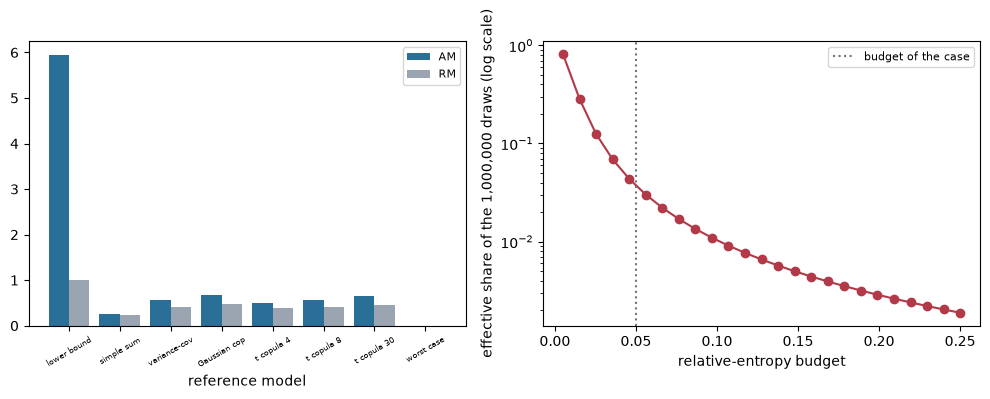

effective draws, budgets 0.005, 0.10, 0.25 [812078, 10948, 1883]


In [15]:
# Draw AM and RM by reference model, and the effective sample size against the budget
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
tags = [NAMES[m][:12] + (f" {nu:g}" if nu else "") for m, nu in labels]
axes[0].bar(np.arange(8) - 0.2, [r.am for r in by_reference], width=0.4, color="#2a6f97", label="AM")
axes[0].bar(np.arange(8) + 0.2, [r.rm for r in by_reference], width=0.4, color="#9aa5b1", label="RM")
axes[0].set_xticks(range(8))
axes[0].set_xticklabels(tags, fontsize=6, rotation=30)
axes[0].set_xlabel("reference model")
axes[0].legend(fontsize=8)
axes[1].semilogy(budgets, ess, marker="o", color="#b23a48")
axes[1].axvline(0.05, color="#6c757d", linestyle=":", label="budget of the case")
axes[1].set_xlabel("relative-entropy budget")
axes[1].set_ylabel("effective share of the 1,000,000 draws (log scale)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
counts = [round(float(ess[k] * total.size)) for k in (0, 9, 24)]
print("effective draws, budgets 0.005, 0.10, 0.25", counts)


The left panel shows that model risk is a property of the reference as much as of the set. With the lower bound as the reference the add-on multiplier is 5.9469 and the relative measure 1.0000, with the worst case as the reference both are 0, and the Gaussian row, the case's choice, gives 0.6735 and 0.4701; the other rows give a relative measure from 0.2345 (the simple sum) to 0.4600 (the t copula with 30 degrees of freedom). Choosing another reference moves AM from 0 to 5.95 and RM from 0 to 1, so a model-risk figure without its reference is not a number. The set matters as much. Dropping the worst case halves the multiplier, from 0.6735 to 0.3376, and dropping both bounds leaves the same 0.3376 but makes the Gaussian row the best of the set, RM 1.0000, instead of 47 percent of the way down. That 0.3376 is the additive overestimate of notebook 01, because without the bounds the simple sum is the worst row, and it lies inside the 30 to 40 percent of Rosenberg and Schuermann: the same band, read with and without its bounds, gives a model-risk multiplier of 0.34 or of 0.67.

The right panel is the limit of the entropy tilt. At a budget of 0.005 the tilt keeps 81 percent of the million draws effectively in use (812,078 draws); at a budget of 0.046 it keeps 4.4 percent, at 0.097 about 1.1 percent (10,948 draws) and at 0.25 about 0.19 percent (1,883 draws). The case's budget of 0.05 sits where the sample has already lost more than nineteen of every twenty draws, so its worst expected loss rests on a few tens of thousands of draws, still enough to read, while at 0.25 it rests on fewer than two thousand and its tail is the sample's and not the loss's. Where the method breaks: a budget larger than the sample can carry reweights the noise of the tail, and the engine refuses only the budgets above the logarithm of the sample size, not those that merely leave little sample. The sweep varies the budget on one simulation with the case's seed.

### Using it on your own data

The two measures take plain numbers. `barrieu_scandolo` needs the capital of each model of your set, in one money unit and on one basis, and the index of the reference model; `glasserman_xu_worst_case` needs a sample of the loss whose expectation you are questioning and a budget. Both return a result whose numbers the product writes in the `model_risk` block of an aggregation document, labelled `information-not-capital`. The contract is `engine-aggregation-api` (`docs/contracts/engine/aggregation-api.md`), which fixes the two signatures, their refusals (a reference outside the set, a budget the sample cannot reach) and the fields of the block.

The next cell reads the block that the baseline document commits and lists the fields of the block, of the Barrieu and Scandolo result and of the Glasserman and Xu result, and checks the identity that links them: the reference capital times $1 + \mathrm{AM}$ is the worst capital of the set.

In [16]:
# Read the committed model-risk block and list its fields
block = agg["model_risk"]
print("top-level fields of model_risk", sorted(block))
print("fields of barrieu_scandolo", sorted(block["barrieu_scandolo"]))
print("fields of glasserman_xu", sorted(block["glasserman_xu"]))
print("status, set and reference", block["status"], block["set_of_models"], block["reference_model"])
bs = block["barrieu_scandolo"]
worst_row = bs["rho_x0_clp_m"] * (1 + bs["am"])
print("reference times (1 + AM) is the worst row", np.isclose(worst_row, bs["rho_max_clp_m"]))


top-level fields of model_risk ['barrieu_scandolo', 'glasserman_xu', 'label', 'reference_model', 'set_of_models', 'status']
fields of barrieu_scandolo ['am', 'rho_max_clp_m', 'rho_min_clp_m', 'rho_x0_clp_m', 'rm']
fields of glasserman_xu ['baseline_clp_m', 'quantity', 'relative_entropy_budget', 'theta', 'worst_case_clp_m']
status, set and reference information-not-capital band-rows {'method': 'gaussian-copula', 'nu': None}
reference times (1 + AM) is the worst row True


The `model_risk` block has six fields: `status` and `label`, which state that it is information and not capital, `set_of_models`, here the rows of the band, the `reference_model` and the two results. `barrieu_scandolo` holds the reference capital (`rho_x0_clp_m`), the worst and the best of the set (`rho_max_clp_m`, `rho_min_clp_m`) and the two measures `am` and `rm`; `glasserman_xu` holds the baseline and the worst-case expected loss, the budget, the tilt `theta` and the `quantity` it questions. The identity holds: the reference capital times $1 + \mathrm{AM}$ is the worst row.

To use the measures on numbers of your own, the next cell does two things. It reads the market-credit stress band of the second committed document, the same eight rows computed with the correlation raised to 0.8, and measures its model risk with the Gaussian row as the reference; and it draws 200,000 losses from a lognormal law with a fixed seed, a stand-in for your own simulated losses, and calls `glasserman_xu_worst_case` on them at the case's budget of 0.05.

In [17]:
# Your own numbers: the stressed band as a set of models, and a worst case on a sample of your own
stressed = read_json("C18/t-copula-baseline.json")["outputs"]["correlation_stress"]["aggregation"]["band"]
stress_caps = [row["capital_clp_m"] for row in stressed]
stress_labels = [(row["method"], row["nu"]) for row in stressed]
mine_bs = model_risk.barrieu_scandolo(stress_caps, stress_labels.index(("gaussian-copula", None)))
base_bs = model_risk.barrieu_scandolo(capitals, reference)
rng = np.random.default_rng(11)
my_losses = rng.lognormal(10.0, 1.1, 200_000)
my_gx = model_risk.glasserman_xu_worst_case(my_losses, 0.05)
print("base band, AM and RM", round(base_bs.am, 4), round(base_bs.rm, 4))
print("stressed band, AM and RM", round(mine_bs.am, 4), round(mine_bs.rm, 4))
print("stressed reference, CLP millions", round(mine_bs.rho_x0))
print("worst and best of the stressed set", round(mine_bs.rho_max), round(mine_bs.rho_min))
print("your sample: baseline and worst case", round(my_gx.baseline), round(my_gx.worst_case))
print("worst case over baseline", round(my_gx.worst_case / my_gx.baseline, 3))
print("entropy reached and tilt", round(my_gx.relative_entropy, 4), f"{my_gx.theta:.3e}")


base band, AM and RM 0.6735 0.4701
stressed band, AM and RM 0.4927 0.3856
stressed reference, CLP millions 551569
worst and best of the stressed set 823332 118517
your sample: baseline and worst case 40174 81801
worst case over baseline 2.036
entropy reached and tilt 0.05 1.516e-06


On the stressed band the add-on multiplier is 0.4927 and the relative measure 0.3856, against 0.6735 and 0.4701 on the base band. The two bounds, 118,517 and 823,332 million, have not moved, but the Gaussian reference has, from 491,974 to 551,569, nearer to the worst case, so the multiplier falls: a model-risk figure read alone would call the more correlated book less exposed to its model, when its capital has risen by 12 percent. The two measures must be read with the capital they refer to. On your sample the worst expected loss within the budget of 0.05 is 81,801 against a baseline of 40,174, 2.036 times, close to the 2.14 of the case on its heavy-tailed aggregate, with the entropy reached at 0.05 and a tilt of 1.516e-06.

What to check in your own output: that the set and the reference are written beside the result; that every capital of the set is in the same money unit and on the same basis; that `glasserman_xu_worst_case` reaches the budget, which the printed entropy of 0.05 shows; and the effective sample size, which the sweep showed falls fast as the budget grows. What this does not show: the lognormal sample is a stand-in for your own simulation.

The table of this notebook starts with a method that cannot be run here, the Federal Reserve's supervisory models, which is also the method that the product plans as its supervisory replication. Their published structure is a loss per facility,

$$\mathrm{EL} = \sum_{i} \mathrm{PD}_i \times \mathrm{LGD}_i \times \mathrm{EAD}_i,$$

where $\mathrm{PD}_i$, $\mathrm{LGD}_i$ and $\mathrm{EAD}_i$ are the probability of default, the loss given default and the exposure at default of facility $i$, the PD coming from regressions on the BBB spread (Federal Reserve, Fall 2026 credit risk model documentation, in the references). Reproducing the published loss rates of the hypothetical portfolios from it is the acceptance criterion of that replication, and the committed records say it is not met here: notebook 09 reads the three records that keep the replication planned, the engine's contract has no supervisory function or test, and no committed document holds a published loss rate. This notebook teaches the structure and the comparison and reports no replication.

## Results

The case sits inside the published practice on the points where it can be measured, and its distance to it is stated. The
additive overestimate of 0.3376 is inside the published 30 to 40 percent range, the t copula with four degrees of freedom is
12.3 percent above the Gaussian one, which is a larger copula effect than the paper's modest one, and the back-cast peak
ratios, 2.09 to 252.13, say that the stressed credit loss rests on satellites that fail their own validation (notebook 07).

**Answer:** one capital figure hides a great deal. The Gaussian reference of CLP 491,974 million is 47 percent of the way down
from the worst case of 823,332 million to the best of 118,518, the add-on multiplier is 0.6735 (the worst case is 1.67 times the
reference), and an entropy budget of 0.05 on the simulated aggregate lifts its expected loss from 66,899 to 143,207 million,
2.14 times, with 4.74 times at a budget of 0.20. What the case lacks is stated: the Federal Reserve models cannot be replicated
to a published loss rate from the public record, vine copulas and the Minnesota BVAR are not in the engine, and the first step of
growth-at-risk needs a package this environment lacks.

What this notebook does not show: the Glasserman-Xu figures are on an aggregate simulated from a grid of 1,961 points per
marginal, which agrees with the committed block to 0.01 percent and not to the digit; the table of the published literature is the
research's, with its UNVERIFIED items marked, not a fresh literature review; and no number in it is a regulatory result.

The VAR conditional forecast and growth-at-risk beside the satellites run and recover a known system (the conditional rate path peaks
at 5.56 % against a true 5.23 %), but on the Board's history the VAR is closer than OLS in 1 of 5 loan types in 2008-09 and 5 of 5
in the pandemic, with 9 of 10 expected signs wrong, and growth-at-risk beats the unconditional quantile only in 2008-09.

## Summary

- The published practice has three layers: supervisory models (Federal Reserve, EBA), scenario generators (BVAR, GVAR, growth-at-risk, panel quantile) and aggregation (copulas, vines, the Joint Forum's caution); the case implements a simpler satellite family, the EBA static rules, a VAR and skewed-t mechanics, and the Gaussian, t and worst-case ladder.
- Model risk over the band is measured by the add-on multiplier and relative measure of Barrieu and Scandolo, which the engine recomputes exactly from the committed capitals, and by the Glasserman-Xu worst case within an entropy budget, which needs the simulated aggregate and tilts it towards its large losses.
- Both measures are sensitivity information for the validator, labelled `information-not-capital`, and say what one capital figure hides.
- What the engine does not have is stated, not hidden: vine copulas, the Minnesota BVAR, the panel quantile satellite and the first step of growth-at-risk (it needs `statsmodels`); the Federal Reserve models cannot be replicated to a published loss rate from the public record.

**What to try next.** Change the reference model of step 1 to the t copula with $\nu = 4$ and see how the add-on multiplier and relative measure move; then continue with notebook 09, which turns the band into a claim and reads the declared readiness of the case.

- The VAR conditional forecast and growth-at-risk recover a known system, but on the Board's history the VAR wins the pandemic and loses the crisis with 9 of 10 signs wrong.

## References

- Glasserman, P. and Xu, X. (2014), Robust risk measurement and model risk, Quantitative Finance 14(1). https://doi.org/10.1080/14697688.2013.822989
- Barrieu, P. and Scandolo, G. (2015), Assessing financial model risk, European Journal of Operational Research 242(2). https://doi.org/10.1016/j.ejor.2014.10.032
- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation. https://www.bis.org/publ/joint25.pdf
- Bank for International Settlements (2010), press release of 21 October 2010 on the Joint Forum report Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Board of Governors of the Federal Reserve System (2026), Supervisory Stress Test Model Documentation: Credit Risk Models, Fall 2026. https://www.federalreserve.gov/supervisionreg/files/fall-2026-credit-risk-models-description.pdf
- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Adrian, T., Boyarchenko, N. and Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Litterman, R. B. (1986), Forecasting with Bayesian vector autoregressions: five years of experience, Journal of Business and Economic Statistics 4(1). https://doi.org/10.1080/07350015.1986.10509491
- Banbura, M., Giannone, D. and Reichlin, L. (2010), Large Bayesian vector auto regressions, Journal of Applied Econometrics 25(1). https://doi.org/10.1002/jae.1137
- Covas, F., Rump, B. and Zakrajsek, E. (2014), the panel quantile satellite, and Pesaran, Schuermann and Weiner (2004), the global VAR, as summarised in dossier 05, H.2 (no link: not read in this repository's research basis).
- This repository: `docs/contracts/engine/aggregation-api.md` (the model-risk functions).

- Adrian, T., Boyarchenko, N. and Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4), 1263-1289, https://doi.org/10.1257/aer.20161923
- Waggoner, D. F. and Zha, T. (1999), Conditional forecasts in dynamic multivariate models, Review of Economics and Statistics 81(4), 639-651, https://doi.org/10.1162/003465399558508